# 11 - The later batch

The last test. Batch 3 was cycled about a year after batches 1 and 2, with a changed test setup and mostly different charging policies (notebook 05). The paper calls it the secondary test set. If a model only learned the quirks of batches 1 and 2, this is where it shows.

The model is the one from notebook 08, fitted on the 41 training cells, exactly as it was scored on the primary test set in notebook 09. It gets scored on these 40 cells once. Whatever comes out, I don't go back and change features or settings.

One thing to be open about: I had already seen the straight line's score on this batch once, while checking in Stage 2 that my pipeline reproduces the paper's number for that model (196 cycles). Nothing was chosen from it. The Elastic Net has never been scored on this batch before this notebook.

In [1]:
import sys
sys.path.append("..")

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

from src.models import elastic_net, mape, rmse

warnings.filterwarnings("ignore", category=UserWarning)

data = pd.read_csv("../data/features_stage3.csv", index_col="cell_id")
train = data[data["split"] == "train"]
primary = data[data["split"] == "test_primary"]
later = data[data["split"] == "test_secondary"]

ALL = ["log_var", "q2", "q_max_minus_q2", "ir_change", "charge_time_first5", "t_avg_mean"]
print(len(train), "training cells,", len(primary), "primary test cells,", len(later), "later-batch cells")

41 training cells, 43 primary test cells, 40 later-batch cells


In [2]:
y_train = np.log10(train["cycle_life"])
line = LinearRegression().fit(train[["log_var"]], y_train)
net = elastic_net().fit(train[ALL], y_train)
print(f"Elastic Net: alpha = {net[-1].alpha_:.4f}, l1_ratio = {net[-1].l1_ratio_} (same as in notebook 09)")

Elastic Net: alpha = 0.0479, l1_ratio = 0.1 (same as in notebook 09)


## Scores

In [3]:
def predict(d):
    return pd.DataFrame({
        "A: mean": train["cycle_life"].mean(),
        "B: log_var line": 10 ** line.predict(d[["log_var"]]),
        "D: Elastic Net": 10 ** net.predict(d[ALL]),
    }, index=d.index)


pred_later = predict(later)
rows = []
for set_name, d in [("train", train), ("primary test", primary), ("later batch", later)]:
    p = predict(d)
    for model in p.columns:
        rows.append({"set": set_name, "model": model,
                     "RMSE (cycles)": rmse(d["cycle_life"], p[model]),
                     "MAPE (%)": mape(d["cycle_life"], p[model])})
scores = pd.DataFrame(rows)
order = ["train", "primary test", "later batch"]
scores.pivot(index="model", columns="set", values="RMSE (cycles)").round(1)[order]

set,train,primary test,later batch
model,,,
A: mean,323.1,392.8,470.3
B: log_var line,103.6,137.9,195.9
D: Elastic Net,76.2,113.7,262.4


In [4]:
scores.pivot(index="model", columns="set", values="MAPE (%)").round(1)[order]

set,train,primary test,later batch
model,,,
A: mean,33.5,39.5,31.2
B: log_var line,14.1,14.7,11.4
D: Elastic Net,10.0,12.8,16.5


## How sure are these numbers?

Same resampling as in notebook 09: 5,000 resamples of the 40 cells, both models on the same resample each time.

In [5]:
rng = np.random.default_rng(0)
y = later["cycle_life"].values
p_line = pred_later["B: log_var line"].values
p_net = pred_later["D: Elastic Net"].values

boot_line, boot_net = [], []
for _ in range(5000):
    k = rng.integers(0, len(y), len(y))
    boot_line.append(rmse(y[k], p_line[k]))
    boot_net.append(rmse(y[k], p_net[k]))
boot_line, boot_net = np.array(boot_line), np.array(boot_net)

for name, b in [("B: log_var line", boot_line), ("D: Elastic Net", boot_net)]:
    low, high = np.percentile(b, [2.5, 97.5])
    print(f"{name}: 95% range {low:.0f} to {high:.0f} cycles")

diff = boot_line - boot_net
low, high = np.percentile(diff, [2.5, 97.5])
print(f"B minus D: {rmse(y, p_line) - rmse(y, p_net):.1f} cycles, 95% range {low:.0f} to {high:.0f}")
print(f"D has the lower RMSE in {np.mean(diff > 0) * 100:.1f}% of the resamples")

closer = np.abs(p_net - y) < np.abs(p_line - y)
print(f"cell by cell, D is closer than B for {closer.sum()} of the {len(y)} cells")

B: log_var line: 95% range 116 to 273 cycles
D: Elastic Net: 95% range 176 to 349 cycles
B minus D: -66.5 cycles, 95% range -93 to -37
D has the lower RMSE in 0.1% of the resamples
cell by cell, D is closer than B for 10 of the 40 cells


## Predicted vs actual

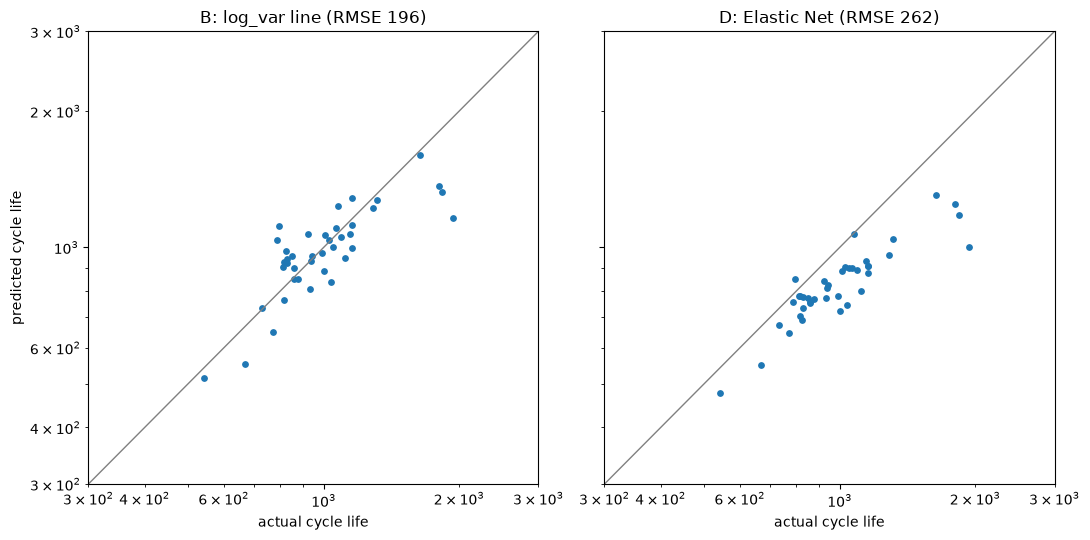

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
lims = [300, 3000]
for ax, model in zip(axes, ["B: log_var line", "D: Elastic Net"]):
    ax.scatter(later["cycle_life"], pred_later[model], s=15)
    ax.plot(lims, lims, color="grey", linewidth=1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("actual cycle life")
    ax.set_title(f"{model} (RMSE {rmse(later['cycle_life'], pred_later[model]):.0f})")
axes[0].set_ylabel("predicted cycle life")
plt.tight_layout()
plt.savefig("../reports/figures/pred_vs_actual_later_batch.png", dpi=120)
plt.show()

## Where the errors are

In [7]:
errors = pred_later[["B: log_var line", "D: Elastic Net"]].sub(later["cycle_life"], axis=0)
for model in errors.columns:
    e = errors[model]
    print(f"{model}: mean error {e.mean():+.0f} cycles, {(e < 0).sum()} of {len(e)} cells predicted too short")

long_cells = later["cycle_life"] > 1500
for model in errors.columns:
    e = errors[model]
    print(f"{model}: {long_cells.sum()} cells above 1,500 cycles RMSE {np.sqrt(np.mean(e[long_cells] ** 2)):.0f}, the other {(~long_cells).sum()} cells RMSE {np.sqrt(np.mean(e[~long_cells] ** 2)):.1f}")

table = errors.round(0).astype(int)
table.insert(0, "actual", later["cycle_life"].astype(int))
worst = errors["D: Elastic Net"].abs().sort_values(ascending=False).index[:6]
print("largest errors of D (predicted minus actual, cycles):")
table.loc[worst]

B: log_var line: mean error -34 cycles, 23 of 40 cells predicted too short
D: Elastic Net: mean error -190 cycles, 39 of 40 cells predicted too short
B: log_var line: 4 cells above 1,500 cycles RMSE 512, the other 36 cells RMSE 116.2
D: Elastic Net: 4 cells above 1,500 cycles RMSE 656, the other 36 cells RMSE 169.5
largest errors of D (predicted minus actual, cycles):


,actual,B: log_var line,D: Elastic Net
cell_id,,,
b3c38,1935,-774,-933
b3c7,1836,-509,-656
b3c45,1801,-435,-553
b3c16,1638,-37,-336
b3c33,1284,-65,-323
b3c3,1115,-170,-312


## Is the later batch different in the features the model uses?

For each feature: the range of the training cells, the median of the training cells and of the later batch, and how many later-batch cells fall outside the training range.

In [8]:
rows = []
for f in ALL:
    lo, hi = train[f].min(), train[f].max()
    rows.append({"feature": f, "train min": lo, "train max": hi,
                 "train median": train[f].median(), "later median": later[f].median(),
                 "later cells outside train range": int(((later[f] < lo) | (later[f] > hi)).sum())})
shift = pd.DataFrame(rows).set_index("feature")
shift.round(4)

,train min,train max,train median,later median,later cells outside train range
feature,,,,,
log_var,-5.0140,-2.7457,-3.6199,-4.1509,0
q2,1.0480,1.0939,1.0745,1.0653,2
q_max_minus_q2,0.0016,0.0111,0.0049,0.0032,3
ir_change,-0.0010,0.0002,-0.0000,-0.0001,3
charge_time_first5,8.9647,13.4092,10.1474,10.0434,0
t_avg_mean,29.8071,33.7738,32.7593,34.1124,24


## Why does the Elastic Net do worse here?

The features are scaled with the training cells, so a training cell has a scaled value of 0 on average. A mean scaled value far from 0 in another set means that set is shifted. Multiplied by the coefficient, it shows how much each feature pushes the predictions of that set up or down.

In [9]:
scaler, model = net[0], net[-1]
table = pd.DataFrame({"coefficient": model.coef_}, index=ALL)
for name, d in [("primary test", primary), ("later batch", later)]:
    z = pd.DataFrame(scaler.transform(d[ALL]), index=d.index, columns=ALL)
    push = (z * model.coef_).mean()
    table[f"{name}: mean scaled value"] = z.mean()
    table[f"{name}: push on predicted life (%)"] = (10 ** push - 1) * 100
table.round(2)

,coefficient,primary test: mean scaled value,primary test: push on predicted life (%),later batch: mean scaled value,later batch: push on predicted life (%)
log_var,-0.12,-0.15,4.19,-1.33,42.43
q2,0.03,0.03,0.19,-1.27,-7.77
q_max_minus_q2,-0.02,-0.06,0.27,-1.10,5.09
ir_change,0.00,-0.24,0.00,0.35,0.00
charge_time_first5,0.03,0.07,0.56,-0.48,-3.73
t_avg_mean,-0.00,0.10,0.00,1.61,0.00


In [10]:
sd = train["log_var"].std(ddof=0)
line_weight = line.coef_[0] * sd
z_logvar = ((later["log_var"] - train["log_var"].mean()) / sd).mean()
print(f"weight on scaled log_var: line {line_weight:.3f}, Elastic Net {model.coef_[0]:.3f}")
print(f"later batch, mean scaled log_var {z_logvar:.2f}: this raises the line's prediction by {(10 ** (line_weight * z_logvar) - 1) * 100:.0f}% and the Elastic Net's by {(10 ** (model.coef_[0] * z_logvar) - 1) * 100:.0f}%")

print(f"later cells with q2 below the training median: {(later['q2'] < train['q2'].median()).sum()} of {len(later)}")

fast = train[train["charge_time_first5"] < 10.5]
slow = train.drop(index=fast.index)
print(f"training cells charging in under 10.5 min: {len(fast)}, median life {fast['cycle_life'].median():.0f}; the other {len(slow)}: median life {slow['cycle_life'].median():.0f}")
print(f"later batch: {(later['charge_time_first5'] < 10.5).sum()} of {len(later)} charge in under 10.5 min, median life {later['cycle_life'].median():.0f}")

weight on scaled log_var: line -0.146, Elastic Net -0.115
later batch, mean scaled log_var -1.33: this raises the line's prediction by 57% and the Elastic Net's by 42%
later cells with q2 below the training median: 40 of 40
training cells charging in under 10.5 min: 29, median life 489; the other 12: median life 865
later batch: 36 of 40 charge in under 10.5 min, median life 964


## Save

In [11]:
out = pred_later.round(1)
out.insert(0, "cycle_life", later["cycle_life"])
out.to_csv("../reports/predictions_later_batch.csv")
scores.round(2).to_csv("../reports/final_results.csv", index=False)
print("saved", len(out), "predictions")

saved 40 predictions


## Notes

- The result is the opposite of the primary test set. On the later batch the straight line gets 195.9 cycles (11.4%) and the Elastic Net 262.4 cycles (16.5%). The model I chose is 66.5 cycles worse than the simple one here.
- This isn't noise. The 95% range of the difference is 37 to 93 cycles in the line's favour, the line wins in 99.9% of the resamples, and cell by cell the Elastic Net is closer for only 10 of the 40.
- The line again matches the paper (196 cycles on this batch). The paper saw the same reversal with its own bigger model: 100 cycles on the primary test and 214 on this batch, against 138 and 196 for the variance model (quoted in Attia et al. 2021). So more features helping on the first test set and hurting on the later batch is not special to my features.
- The Elastic Net's error is one-sided. It predicts 39 of the 40 cells too short, by 190 cycles on average. The line is off by 34 cycles on average and too short for 23 of 40.
- Why: this batch sits somewhere else in feature space. Compared with the training cells, its log_var is 1.33 standard deviations lower, its capacity at cycle 2 is 1.27 lower (all 40 cells are below the training median), and its early capacity rise is 1.10 lower. On the primary test set no feature is shifted by more than 0.24.
- The Elastic Net trusts log_var less than the line does (weight -0.115 against -0.146), because in training it could spread that information over charge time and the capacity features. On this batch, log_var says "these cells live much longer": that lifts the line's predictions by 57% and the Elastic Net's by only 42%.
- The other features then pull the wrong way. The lower capacity at cycle 2 takes 7.8% off the predictions and the charge time another 3.7%. In training, charging in under 10.5 minutes went with a short life (29 cells, median 489 cycles, against 865 for the 12 slower ones). In this batch 36 of 40 cells charge that fast and the median life is 964 cycles. What the model learned about charge time and starting capacity was true for batches 1 and 2 and isn't true here.
- The long-lived cells are hard for both models again: RMSE 512 (line) and 656 (Elastic Net) on the 4 cells above 1,500 cycles, 116.2 and 169.5 on the other 36.
- Cross-validation couldn't have warned me. Every fold was drawn from batches 1 and 2, so it only measured how well a model does on more cells of the same kind. To test for this, the folds would have to be whole batches. With two training batches that's a thin check, but it is the one I would add next.
- I'm not going back to retune. Both results stand: the Elastic Net is better on new cells from the same batches (113.7 against 137.9), and the one-feature line holds up better on a batch from a changed setup (195.9 against 262.4). If I had to pick one model for cells from an unknown setup, it would be the line.